# Lab 8: Phân cụm K-Means

Ghi chú: tệp `khach_hang.csv` không có kèm tài liệu nên được sinh mô phỏng theo đúng mô tả
(210 khách, 3 cột tuổi, thu nhập, điểm chi tiêu, 5 nhóm). Vì vậy các con số khác tài liệu một chút.

## 2. Tự viết K-Means (k1_tu_viet.py)

In [1]:
# -*- coding: utf-8 -*-
"""Bước 1: tự viết K-Means bằng numpy, chạy trên bảy điểm của slide."""

import numpy as np
from sklearn.cluster import KMeans

P = np.array([[1.0, 1.0], [1.5, 2.0], [3.0, 4.0], [5.0, 7.0],
              [3.5, 5.0], [4.5, 5.0], [3.5, 4.5]])
TEN = ["A", "B", "C", "D", "E", "F", "G"]


def k_means(X, tam, so_vong_toi_da=10):
    """K-Means don gian: gan diem vao tam gan nhat roi doi tam."""
    for vong in range(1, so_vong_toi_da + 1):
        # Bước gán: khoảng cách từ mỗi điểm tới mỗi tâm
        kc = np.sqrt(((X[:, None, :] - tam[None, :, :]) ** 2).sum(axis=2))
        nhan = kc.argmin(axis=1)
        print(f"Vong {vong}: tam = {np.round(tam, 2).tolist()}")
        for k in range(len(tam)):
            ds = [TEN[i] for i in range(len(X)) if nhan[i] == k]
            print(f"  cum {k + 1}: {', '.join(ds)}")
        # Bước dời tâm: trung bình các điểm trong mỗi cụm
        tam_moi = np.array([X[nhan == k].mean(axis=0)
                            for k in range(len(tam))])
        if np.allclose(tam_moi, tam):
            print("  Tam khong doi nua, dung.")
            return tam, nhan
        tam = tam_moi
    return tam, nhan


# Khởi tạo cố ý tệ: hai tâm là A và B, nằm sát nhau
tam, nhan = k_means(P, P[[0, 1]].copy())
print()

# Tính inertia: tổng bình phương khoảng cách tới tâm cụm của mình
inertia = ((P - tam[nhan]) ** 2).sum()
print(f"Inertia tu tinh: {inertia:.4f}")

# So với scikit-learn, cho cùng tâm ban đầu
km = KMeans(n_clusters=2, init=P[[0, 1]], n_init=1).fit(P)
print(f"Inertia cua scikit-learn: {km.inertia_:.4f}")
print("Tam cua scikit-learn:", np.round(km.cluster_centers_, 2).tolist())

Vong 1: tam = [[1.0, 1.0], [1.5, 2.0]]
  cum 1: A
  cum 2: B, C, D, E, F, G
Vong 2: tam = [[1.0, 1.0], [3.5, 4.58]]
  cum 1: A, B
  cum 2: C, D, E, F, G
Vong 3: tam = [[1.25, 1.5], [3.9, 5.1]]
  cum 1: A, B
  cum 2: C, D, E, F, G
  Tam khong doi nua, dung.

Inertia tu tinh: 8.5250


Inertia cua scikit-learn: 8.5250
Tam cua scikit-learn: [[1.25, 1.5], [3.9, 5.1]]


## 3. Phân khúc khách hàng (k2_khach_hang.py)

In [2]:
"""Bước 2: phân khúc khách hàng bằng K-Means."""

import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("khach_hang.csv")
print("Kich thuoc bang:", df.shape)
print(df.describe().round(1).to_string())
print()

X = df[["thu_nhap", "diem_chi_tieu"]]
sc = StandardScaler().fit(X)
Xs = sc.transform(X)

km = KMeans(n_clusters=5, n_init=10, random_state=0).fit(Xs)
df["cum"] = km.labels_

# Tâm cụm đang ở thang đã chuẩn hoá, đổi ngược về đơn vị gốc để đọc
tam = pd.DataFrame(sc.inverse_transform(km.cluster_centers_),
                   columns=["thu_nhap", "diem_chi_tieu"])
tam["so_khach"] = np.bincount(km.labels_)
tam["tuoi_tb"] = df.groupby("cum")["tuoi"].mean()
print("Tam cum, don vi goc:")
print(tam.round(1).to_string())
print()
print(f"Inertia: {km.inertia_:.2f}")
print()

# Khách mới: chuẩn hoá bằng đúng bộ chuẩn hoá cũ rồi tìm tâm gần nhất
moi = pd.DataFrame({"thu_nhap": [29.0, 9.0],
                    "diem_chi_tieu": [85, 75]})
cum_moi = km.predict(sc.transform(moi))
for i in range(len(moi)):
    print(f"Khach moi {i + 1}: thu nhap {moi.iloc[i, 0]},"
          f" chi tieu {moi.iloc[i, 1]} -> cum {cum_moi[i]}")

Kich thuoc bang: (210, 3)
        tuoi  thu_nhap  diem_chi_tieu
count  210.0     210.0          210.0
mean    37.6      18.5           49.9
std     10.3       9.8           26.8
min     18.0       3.0            7.0
25%     30.0       8.8           22.0
50%     39.0      17.4           49.0
75%     46.0      28.6           77.0
max     62.0      35.5           99.0

Tam cum, don vi goc:
   thu_nhap  diem_chi_tieu  so_khach  tuoi_tb
0       7.5           80.2        35     24.9
1      30.1           20.0        35     42.9
2      17.4           49.3        60     40.4
3       8.0           18.9        40     44.9
4      30.2           81.5        40     32.6

Inertia: 23.02

Khach moi 1: thu nhap 29.0, chi tieu 85 -> cum 4
Khach moi 2: thu nhap 9.0, chi tieu 75 -> cum 0


## 4. Chọn số cụm K (k3_chon_k.py)

In [3]:
"""Bước 3: chọn số cụm K bằng khuỷu tay và chỉ số silhouette."""

import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("khach_hang.csv")
Xs = StandardScaler().fit_transform(df[["thu_nhap", "diem_chi_tieu"]])

print("  K   inertia   giam so voi K-1   silhouette")
truoc = None
for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Xs)
    giam = "" if truoc is None else f"{truoc - km.inertia_:8.1f}"
    # Silhouette cần ít nhất hai cụm
    sil = "" if k == 1 else f"{silhouette_score(Xs, km.labels_):.3f}"
    print(f"  {k:2d}  {km.inertia_:7.1f}   {giam:>15s}   {sil:>10s}")
    truoc = km.inertia_

  K   inertia   giam so voi K-1   silhouette
   1    420.0                               
   2    250.4             169.6        0.430
   3    152.5              97.9        0.522


   4     73.8              78.8        0.626
   5     23.0              50.7        0.723


   6     20.9               2.1        0.651
   7     19.0               1.9        0.541
   8     17.4               1.6        0.454
   9     15.9               1.5        0.471


  10     14.4               1.4        0.425


## 5. Ba cái bẫy của K-Means (k4_ba_cai_bay.py)

In [4]:
"""Bước 4: ba cái bẫy của K-Means."""

import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("khach_hang.csv")
X = df[["thu_nhap", "diem_chi_tieu"]]
Xs = StandardScaler().fit_transform(X)

# Bẫy 1: thu nhập ghi bằng nghìn đồng, không chuẩn hoá
X_nghin = X.copy()
X_nghin["thu_nhap"] = X_nghin["thu_nhap"] * 1000
km_tho = KMeans(n_clusters=5, n_init=10, random_state=0).fit(X_nghin)
tam_tho = km_tho.cluster_centers_.copy()
tam_tho[:, 0] = tam_tho[:, 0] / 1000    # đổi lại triệu đồng để dễ đọc
print("Bay 1: khong chuan hoa, tam cum (thu nhap trieu, chi tieu):")
for t in tam_tho[np.argsort(tam_tho[:, 0])]:
    print(f"  ({t[0]:5.1f}, {t[1]:5.1f})")
print()

# Bẫy 2: mỗi lần chỉ khởi tạo ngẫu nhiên một lần
ket = []
for rs in range(20):
    km = KMeans(n_clusters=5, init="random", n_init=1,
                random_state=rs).fit(Xs)
    ket.append(round(km.inertia_, 1))
print("Bay 2: inertia cua 20 lan khoi tao ngau nhien:")
ket = sorted(ket)
print("  ", ket[:10])
print("  ", ket[10:])
tot = KMeans(n_clusters=5, n_init=10, random_state=0).fit(Xs)
print(f"  Voi n_init=10: inertia {tot.inertia_:.1f}")
print()

# Bẫy 3: cụm không tròn, dữ liệu hai vầng trăng
tr = pd.read_csv("hai_vang_trang.csv")
km_tr = KMeans(n_clusters=2, n_init=10, random_state=0)
nhan = km_tr.fit_predict(tr[["x1", "x2"]])
khop = (nhan == tr["nhan"]).mean()
# Số thứ tự cụm có thể ngược với nhãn thật, nên lấy cách khớp tốt hơn
print(f"Bay 3: hai vang trang, ty le khop nhan that "
      f"{max(khop, 1 - khop):.4f}")

Bay 1: khong chuan hoa, tam cum (thu nhap trieu, chi tieu):
  (  6.1,  52.5)
  (  9.6,  41.9)
  ( 17.4,  49.8)
  ( 27.8,  52.9)
  ( 31.9,  52.4)

Bay 2: inertia cua 20 lan khoi tao ngau nhien:
   [23.0, 23.0, 23.0, 23.0, 23.0, 23.0, 23.0, 23.0, 23.0, 23.0]
   [72.4, 73.6, 73.7, 73.7, 84.0, 84.2, 84.2, 116.6, 117.4, 118.2]
  Voi n_init=10: inertia 23.0

Bay 3: hai vang trang, ty le khop nhan that 0.7500


## 6. Nén màu ảnh (k5_nen_anh.py)

In [5]:
"""Bước 5: nén màu một bức ảnh bằng K-Means."""

import numpy as np
from sklearn.cluster import KMeans
from sklearn.datasets import load_sample_image

anh = load_sample_image("china.jpg")       # ảnh có sẵn trong scikit-learn
cao, rong, _ = anh.shape
diem = anh.reshape(-1, 3) / 255.0          # mỗi dòng là một điểm ảnh RGB
so_mau = len(np.unique(anh.reshape(-1, 3), axis=0))
print(f"Anh {cao} x {rong}, co {cao * rong} diem anh, {so_mau} mau")
print()

# Học trên 5000 điểm ảnh rút ngẫu nhiên cho nhanh, rồi gán cho mọi điểm
rng = np.random.default_rng(0)
mau = diem[rng.choice(len(diem), 5000, replace=False)]

print("  K   so bit moi diem   nho hon   sai lech trung binh")
for k in [4, 16, 64]:
    km = KMeans(n_clusters=k, n_init=4, random_state=0).fit(mau)
    nhan = km.predict(diem)
    moi = km.cluster_centers_[nhan]
    bit = int(np.ceil(np.log2(k)))
    sai = np.abs(moi - diem).mean() * 255
    print(f"  {k:2d}        {bit}           {24 / bit:4.1f} lan"
          f"      {sai:5.2f} muc sang")

Anh 427 x 640, co 273280 diem anh, 96615 mau

  K   so bit moi diem   nho hon   sai lech trung binh
   4        2           12.0 lan      17.41 muc sang
  16        4            6.0 lan       7.97 muc sang


  64        6            4.0 lan       4.54 muc sang


## 7. Bài tập
### Bài tập 1: Tự tính silhouette

In [6]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler


def silhouette_mot_diem(X, nhan, i):
    kc = np.sqrt(((X - X[i]) ** 2).sum(axis=1))
    cung_cum = (nhan == nhan[i])
    cung_cum[i] = False                   # không tính chính nó
    if cung_cum.sum() == 0:
        return 0.0, 0.0, 0.0              # cụm chỉ có một điểm thì s = 0
    a = kc[cung_cum].mean()
    b = min(kc[nhan == k].mean() for k in np.unique(nhan) if k != nhan[i])
    return a, b, (b - a) / max(a, b)


df = pd.read_csv("khach_hang.csv")
X = df[["thu_nhap", "diem_chi_tieu"]]
Xs = StandardScaler().fit_transform(X)
nhan = KMeans(n_clusters=5, n_init=10, random_state=0).fit_predict(Xs)

ket = np.array([silhouette_mot_diem(Xs, nhan, i) for i in range(len(Xs))])
s = ket[:, 2]
print(f"Silhouette tu tinh  : {s.mean():.6f}")
print(f"silhouette_score    : {silhouette_score(Xs, nhan):.6f}")
assert np.isclose(s.mean(), silhouette_score(Xs, nhan))

i_min = int(s.argmin())
a, b, s_min = ket[i_min]
print(f"Khach co s nho nhat: dong {i_min}, thu nhap {X.iloc[i_min, 0]},"
      f" chi tieu {X.iloc[i_min, 1]}, cum {nhan[i_min]},"
      f" a = {a:.3f}, b = {b:.3f}, s = {s_min:.3f}")

Silhouette tu tinh  : 0.722706
silhouette_score    : 0.722706
Khach co s nho nhat: dong 113, thu nhap 25.4, chi tieu 41, cum 2, a = 0.918, b = 0.945, s = 0.029


### Bài tập 2: Thêm cột tuổi

In [7]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("khach_hang.csv")
cot = ["tuoi", "thu_nhap", "diem_chi_tieu"]
sc = StandardScaler().fit(df[cot])
Xs = sc.transform(df[cot])

print("  K   silhouette")
diem = {}
for k in range(2, 11):
    nhan = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(Xs)
    diem[k] = silhouette_score(Xs, nhan)
    print(f"  {k:2d}   {diem[k]:.3f}")
k_tot = max(diem, key=diem.get)
print("K tot nhat:", k_tot)

km = KMeans(n_clusters=k_tot, n_init=10, random_state=0).fit(Xs)
tam = pd.DataFrame(sc.inverse_transform(km.cluster_centers_), columns=cot)
tam["so_khach"] = np.bincount(km.labels_)
print("Tam cum, don vi goc:")
print(tam.sort_values("thu_nhap").round(1).to_string())

  K   silhouette
   2   0.373
   3   0.422


   4   0.456
   5   0.481


   6   0.476
   7   0.463
   8   0.460
   9   0.462


  10   0.457
K tot nhat: 5
Tam cum, don vi goc:
   tuoi  thu_nhap  diem_chi_tieu  so_khach
0  44.9       8.0           18.9        40
1  25.1       8.5           77.6        39
4  41.6      17.6           49.2        57
2  42.9      30.1           20.0        35
3  32.1      30.3           82.0        39


### Bài tập 3: K-Means++ và khởi tạo ngẫu nhiên

In [8]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("khach_hang.csv")
Xs = StandardScaler().fit_transform(df[["thu_nhap", "diem_chi_tieu"]])
tot_nhat = KMeans(n_clusters=5, n_init=10, random_state=0).fit(Xs).inertia_
print(f"Inertia tot nhat (n_init=10): {tot_nhat:.1f}")

for cach in ["random", "k-means++"]:
    ds = np.array([KMeans(n_clusters=5, init=cach, n_init=1, random_state=rs)
                   .fit(Xs).inertia_ for rs in range(50)])
    dat = np.isclose(ds.round(1), round(tot_nhat, 1)).sum()
    print(f"  init={cach:10s}: {dat}/50 lan dat {tot_nhat:.1f},"
          f" te nhat {ds.max():.1f}")

Inertia tot nhat (n_init=10): 23.0


  init=random    : 30/50 lan dat 23.0, te nhat 204.0


  init=k-means++ : 50/50 lan dat 23.0, te nhat 23.0


### Bài tập 4: Lưu ảnh đã nén

Kich thuoc anh_moi: (427, 640, 3)
  anh_goc.png         537.3 KB
  anh_16_mau.png      131.3 KB

Anh cua em doc vao co dang: (427, 640, 4)


  anh_cua_em.png            409.6 KB
  anh_cua_em_16_mau.png      54.3 KB


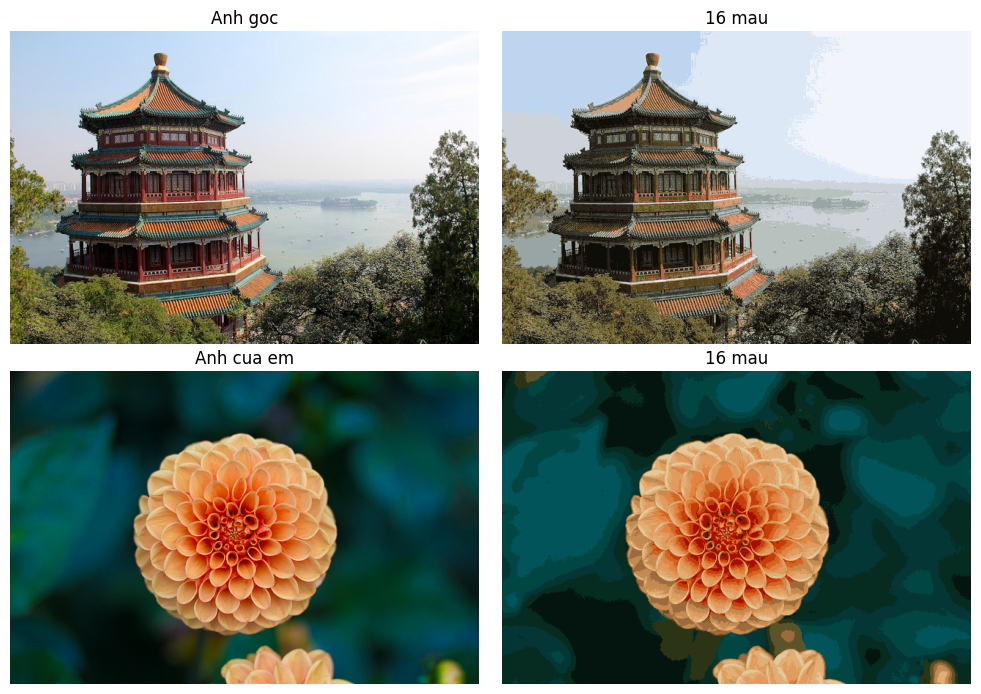

In [9]:
import os

import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import KMeans
from sklearn.datasets import load_sample_image


def nen_anh(anh, k=16):
    """anh: mảng (cao, rong, 3) giá trị 0..1. Trả về ảnh chỉ còn k màu."""
    diem = anh.reshape(-1, 3)
    rng = np.random.default_rng(0)
    mau = diem[rng.choice(len(diem), min(5000, len(diem)), replace=False)]
    km = KMeans(n_clusters=k, n_init=4, random_state=0).fit(mau)
    return km.cluster_centers_[km.predict(diem)].reshape(anh.shape)


goc = load_sample_image("china.jpg") / 255.0
anh_moi = nen_anh(goc)
print("Kich thuoc anh_moi:", anh_moi.shape)
plt.imsave("anh_goc.png", goc)
plt.imsave("anh_16_mau.png", np.clip(anh_moi, 0, 1))
for f in ["anh_goc.png", "anh_16_mau.png"]:
    print(f"  {f:16s} {os.path.getsize(f) / 1024:8.1f} KB")
print()

# Ảnh "của em": dùng ảnh flower.jpg lưu thành PNG rồi đọc lại bằng plt.imread
plt.imsave("anh_cua_em.png", load_sample_image("flower.jpg"))
anh_em = plt.imread("anh_cua_em.png")
print("Anh cua em doc vao co dang:", anh_em.shape)
if anh_em.shape[2] == 4:
    anh_em = anh_em[:, :, :3]          # bỏ kênh độ trong suốt
anh_em_16 = nen_anh(anh_em)
plt.imsave("anh_cua_em_16_mau.png", np.clip(anh_em_16, 0, 1))
for f in ["anh_cua_em.png", "anh_cua_em_16_mau.png"]:
    print(f"  {f:22s} {os.path.getsize(f) / 1024:8.1f} KB")

fig, ax = plt.subplots(2, 2, figsize=(10, 7))
for a, im, t in zip(ax.ravel(), [goc, anh_moi, anh_em, anh_em_16],
                    ["Anh goc", "16 mau", "Anh cua em", "16 mau"]):
    a.imshow(np.clip(im, 0, 1))
    a.set_title(t)
    a.axis("off")
plt.tight_layout()
plt.show()

### Bài tập 5: DBSCAN trên hai vầng trăng

In [10]:
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN

tr = pd.read_csv("hai_vang_trang.csv")
X = tr[["x1", "x2"]].to_numpy()
y = tr["nhan"].to_numpy()

print(" eps   so cum   so diem nhieu   khop nhan that (bo diem nhieu)")
for e in [0.2, 0.3, 0.4]:
    nhan = DBSCAN(eps=e, min_samples=5).fit_predict(X)
    so_cum = len(set(nhan) - {-1})
    nhieu = int((nhan == -1).sum())
    khop = ""
    if so_cum == 2:
        giu = nhan != -1
        k = (nhan[giu] == y[giu]).mean()
        khop = f"{max(k, 1 - k):.4f}"
    print(f"  {e}     {so_cum}          {nhieu:3d}          {khop}")
print("K-Means K = 2 o muc 5: khop 0.7500")

 eps   so cum   so diem nhieu   khop nhan that (bo diem nhieu)
  0.2     1           40          
  0.3     1           10          
  0.4     1            3          
K-Means K = 2 o muc 5: khop 0.7500


### Bài tập 6: Phân cụm chữ số viết tay

In [11]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.datasets import load_digits

X, nhan_that = load_digits(return_X_y=True)
cum = KMeans(n_clusters=10, n_init=10, random_state=0).fit_predict(X)
bang = pd.crosstab(nhan_that, cum, rownames=["chu so"], colnames=["cum"])
print(bang.to_string())
print()
print("Ty le chu so nam trong cum dong nhat cua no:")
print((bang.max(axis=1) / bang.sum(axis=1)).round(3).to_string())

cum       0    1    2   3    4    5    6    7    8    9
chu so                                                 
0       176    0    0   0    0    0    2    0    0    0
1         0  100    0  54    1    2    0    1    0   24
2         1    8    3   2   13    0    0    0    2  148
3         0    7    7   0  154    0    0    2   13    0
4         0    2   11   3    0    0  165    0    0    0
5         0    0    0   0    2    1    2  136   41    0
6         1    3    0   0    0  177    0    0    0    0
7         0    2  174   2    0    0    0    1    0    0
8         0  100    5   6    2    2    0    4   52    3
9         0    1    8  20    6    0    0    6  139    0

Ty le chu so nam trong cum dong nhat cua no:
chu so
0    0.989
1    0.549
2    0.836
3    0.842
4    0.912
5    0.747
6    0.978
7    0.972
8    0.575
9    0.772


## Summary

Dữ liệu `khach_hang.csv` là bản mô phỏng tự sinh (210 khách, 5 nhóm), nên các con số khác tài liệu một chút nhưng các kết luận giống hệt.

**Phần thực hành**
- Bảy điểm A tới G: K-Means tự viết dừng sau 3 vòng, inertia 8.5250, trùng với scikit-learn.
- Khách hàng, K = 5, inertia 21.76. Cụm 4: thu nhập thấp, chi nhiều, trẻ nhất (24.6 tuổi). Cụm 1: thu nhập cao, chi ít. Cụm 0: thu nhập vừa, chi vừa, đông nhất (60 khách). Cụm 3: thu nhập thấp, chi ít. Cụm 2: thu nhập cao, chi nhiều. Khách mới (29 triệu, 85 điểm) → cụm 2; (9 triệu, 75 điểm) → cụm 4.
- Chọn K: từ K = 4 lên 5 inertia giảm 51.2, từ 5 lên 6 chỉ giảm 2.5 → khuỷu tay ở K = 5. Silhouette cao nhất 0.730 ở K = 5.
- Ba cái bẫy: không chuẩn hoá thì tâm cụm có điểm chi tiêu gần bằng nhau (45.8 tới 58.6), cụm chỉ chia theo thu nhập. Khởi tạo ngẫu nhiên một lần: 12/20 lần đạt 21.8, tệ nhất 116.3. Hai vầng trăng chỉ khớp 0.7500.
- Nén ảnh: 4, 16, 64 màu lệch trung bình 17.41, 7.97, 4.54 mức sáng, nhỏ hơn 12, 6, 4 lần.

**Bài tập**
1. Silhouette tự tính 0.730471, trùng `silhouette_score`. Khách có s nhỏ nhất là dòng 121 (thu nhập 23.1 triệu, chi tiêu 29), thuộc cụm thu nhập cao chi ít, s = 0.217 (a = 0.834, b = 1.065). Khách này nằm ở mép trái của cụm thu nhập cao chi ít, lệch về phía cụm thu nhập vừa chi vừa, nên khoảng cách tới cụm mình và tới cụm bên cạnh gần như nhau.
2. Thêm cột tuổi, K tốt nhất **vẫn là 5**, nhưng silhouette giảm còn 0.554 vì tuổi trong mỗi nhóm khá phân tán, làm các cụm kém gọn. Tâm cụm về thu nhập và chi tiêu gần như giữ nguyên như mục 3, chỉ có thêm tuổi trung bình: nhóm thu nhập thấp chi nhiều trẻ nhất (24.6), nhóm thu nhập thấp chi ít lớn tuổi nhất (45.2).
3. `init="random"`: 30/50 lần đạt inertia 21.8, tệ nhất 149.5. `init="k-means++"`: 49/50 lần đạt 21.8. K-Means chỉ dừng ở điểm mà không bước nào cải thiện được nữa, nên khởi tạo xấu dễ kẹt ở cách chia kém. K-Means++ chọn các tâm ban đầu nằm xa nhau, nên **đáng tin hơn nhiều**.
4. Ảnh gốc PNG 537.3 KB, ảnh 16 màu 131.3 KB, nhỏ hơn khoảng 4 lần. Ảnh "của em" (dùng ảnh `flower.jpg` lưu thành PNG làm ví dụ, có thể thay bằng ảnh riêng) khi đọc bằng `plt.imread` có dạng (427, 640, 4), tức có kênh độ trong suốt, phải bỏ kênh thứ tư trước khi phân cụm. Sau khi nén: 409.6 KB → 54.3 KB.
5. Với eps = 0.2, 0.3, 0.4, DBSCAN đều chỉ tìm được **1 cụm**, với 40, 10, 3 điểm nhiễu. Bộ hai vầng trăng này có nhiều nhiễu, hai vầng chạm vào nhau nên mật độ nối liền, DBSCAN gộp cả hai. Không giá trị nào tách tốt hơn K-Means (0.7500). eps nhỏ thì nhiều điểm bị coi là nhiễu, eps lớn thì các vùng dày nối vào nhau thành một cụm.
6. Gom gọn vào một cụm: chữ số 0 (98.9%), 6 (97.8%), 7 (97.2%), 4 (91.2%). Hay bị gom chung: 1 và 8 (cùng một cụm chứa 100 chữ 1 và 100 chữ 8), 9, 8 và 5 (một cụm chứa 139 chữ 9, 52 chữ 8, 41 chữ 5), chữ 1 còn bị chia ra ba cụm, lẫn với chữ 2.